
# 02 - Data Preprocessing
Before performing any analysis or clustering, it is important to clean the dataset.
This notebook will focus on:

- Handling missing values
- Removing duplicates
- Fixing inconsistent data
- Converting data types
- Dropping irrelevant columns

***Import Required Libraries***

In [31]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

## Loading the data 

In [32]:
DATA_PATH = "../data/raw/anime.csv"
anime_df = pd.read_csv(DATA_PATH)
anime_df.head()

,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266


## Checking the missing values

we check the missing values and decide how to handle them 

In [33]:
missing = anime_df.isnull().sum().sort_values(ascending=False)
display(missing)
print("missing vlaues percentage")
print (missing * 100 / len(anime_df))

rating      230
genre        62
type         25
anime_id      0
name          0
episodes      0
members       0
dtype: int64

missing vlaues percentage
rating      1.870831
genre       0.504311
type        0.203351
anime_id    0.000000
name        0.000000
episodes    0.000000
members     0.000000
dtype: float64


In [34]:
anime_df['rating'] = anime_df['rating'].fillna(anime_df['rating'].median())
anime_df['genre'] = anime_df['genre'].fillna('Unknown')
anime_df['type'] = anime_df['type'].fillna(anime_df['type'].mode()[0])

### Handling Missing Values
- `rating` had 1.87% missing values and was imputed using the median to reduce the effect of outliers.
- `genre` missing values were labeled as `Unknown` to preserve categorical information.
- `type` missing values were filled using the most frequent category (mode).
- No rows or columns were removed since the missing rate was negligible (<2%).


In [35]:
anime_df[~anime_df['rating'].between(1, 10)]

,anime_id,name,genre,type,episodes,rating,members


In [36]:
anime_df['episodes'].unique()

array(['1', '64', '51', '24', '10', '148', '110', '13', '201', '25', '22',
       '75', '4', '26', '12', '27', '43', '74', '37', '2', '11', '99',
       'Unknown', '39', '101', '47', '50', '62', '33', '112', '23', '3',
       '94', '6', '8', '14', '7', '40', '15', '203', '77', '291', '120',
       '102', '96', '38', '79', '175', '103', '70', '153', '45', '5',
       '21', '63', '52', '28', '145', '36', '69', '60', '178', '114',
       '35', '61', '34', '109', '20', '9', '49', '366', '97', '48', '78',
       '358', '155', '104', '113', '54', '167', '161', '42', '142', '31',
       '373', '220', '46', '195', '17', '1787', '73', '147', '127', '16',
       '19', '98', '150', '76', '53', '124', '29', '115', '224', '44',
       '58', '93', '154', '92', '67', '172', '86', '30', '276', '59',
       '72', '330', '41', '105', '128', '137', '56', '55', '65', '243',
       '193', '18', '191', '180', '91', '192', '66', '182', '32', '164',
       '100', '296', '694', '95', '68', '117', '151', '130',

In [37]:
anime_df['episodes'] = pd.to_numeric(anime_df['episodes'], errors='coerce')

In [38]:
anime_df['episodes'].unique()

array([1.000e+00, 6.400e+01, 5.100e+01, 2.400e+01, 1.000e+01, 1.480e+02,
       1.100e+02, 1.300e+01, 2.010e+02, 2.500e+01, 2.200e+01, 7.500e+01,
       4.000e+00, 2.600e+01, 1.200e+01, 2.700e+01, 4.300e+01, 7.400e+01,
       3.700e+01, 2.000e+00, 1.100e+01, 9.900e+01,       nan, 3.900e+01,
       1.010e+02, 4.700e+01, 5.000e+01, 6.200e+01, 3.300e+01, 1.120e+02,
       2.300e+01, 3.000e+00, 9.400e+01, 6.000e+00, 8.000e+00, 1.400e+01,
       7.000e+00, 4.000e+01, 1.500e+01, 2.030e+02, 7.700e+01, 2.910e+02,
       1.200e+02, 1.020e+02, 9.600e+01, 3.800e+01, 7.900e+01, 1.750e+02,
       1.030e+02, 7.000e+01, 1.530e+02, 4.500e+01, 5.000e+00, 2.100e+01,
       6.300e+01, 5.200e+01, 2.800e+01, 1.450e+02, 3.600e+01, 6.900e+01,
       6.000e+01, 1.780e+02, 1.140e+02, 3.500e+01, 6.100e+01, 3.400e+01,
       1.090e+02, 2.000e+01, 9.000e+00, 4.900e+01, 3.660e+02, 9.700e+01,
       4.800e+01, 7.800e+01, 3.580e+02, 1.550e+02, 1.040e+02, 1.130e+02,
       5.400e+01, 1.670e+02, 1.610e+02, 4.200e+01, 

In [39]:
anime_df['episodes'].isna().sum()

340

In [40]:
len(anime_df)

12294

we will add missing flags for the nan values in the episodes feature

In [41]:
anime_df['missing_episodes'] = anime_df['episodes'].isna().astype(int)

In [42]:
anime_df.loc[anime_df['episodes'] <= 0, 'episodes'] = np.nan

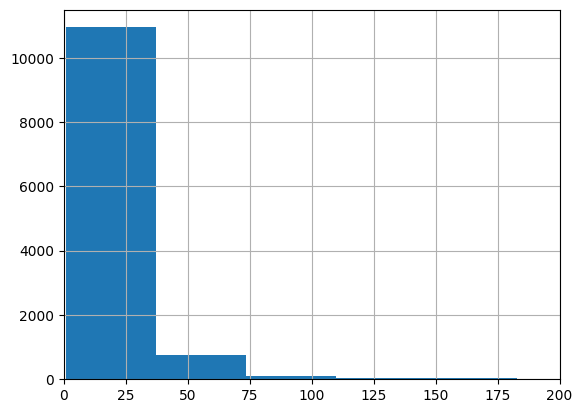

In [43]:
anime_df['episodes'].hist(bins=50)
plt.xlim(0, 200)
plt.show()

In [44]:
anime_df['episodes'].describe()

count    11954.000000
mean        12.382550
std         46.865352
min          1.000000
25%          1.000000
50%          2.000000
75%         12.000000
max       1818.000000
Name: episodes, dtype: float64

In [45]:
anime_df['episodes'] = anime_df['episodes'].astype('Int64')

In [46]:
print(anime_df['episodes'].isna().sum())
anime_df['episodes'].dtype

340


Int64Dtype()

Only 2.8% of episode values were missing. These were preserved and
explicitly encoded using a missing-value indicator to retain information.


In [47]:
anime_df['anime_id'].isna().sum()

0

In [48]:
anime_df['anime_id'].duplicated().sum()

0

In [49]:
anime_df = anime_df.drop(columns = ['anime_id'])

##### After checking `anime_id` column
- No missing values (`NaN`) found.
- No duplicate IDs found.
- since `anime_id` is only an identifier and does not provide meaningful information for clustering, the column was dropped from the dataset.

In [50]:
anime_df['genre'] = anime_df['genre'].str.strip()

In [51]:
anime_df['genre'].isna().sum()

0

In [52]:
anime_df['genre'].unique()

array(['Drama, Romance, School, Supernatural',
       'Action, Adventure, Drama, Fantasy, Magic, Military, Shounen',
       'Action, Comedy, Historical, Parody, Samurai, Sci-Fi, Shounen',
       ..., 'Hentai, Sports', 'Drama, Romance, School, Yuri',
       'Hentai, Slice of Life'], dtype=object)

`genre` doesnt contain missing values

In [53]:
anime_df['type'] = anime_df['type'].str.lower().str.strip()

In [54]:
anime_df['type'] = anime_df['type'].fillna('unkown')

In [55]:
anime_df['type'].replace({
    'tv series': 'tv',
    'tv show': 'tv'
}, inplace=True)

C:\Users\User\AppData\Local\Temp\ipykernel_15232\3159558665.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  anime_df['type'].replace({


In [56]:
anime_df.loc[anime_df['members'] < 0, 'members'] = np.nan

We apply a log transformation to the 'members' feature because it is highly skewed.

In [57]:
anime_df['log_members']= np.log1p(anime_df['members'])

In [58]:
anime_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   name              12294 non-null  object 
 1   genre             12294 non-null  object 
 2   type              12294 non-null  object 
 3   episodes          11954 non-null  Int64  
 4   rating            12294 non-null  float64
 5   members           12294 non-null  float64
 6   missing_episodes  12294 non-null  int32  
 7   log_members       12294 non-null  float64
dtypes: Int64(1), float64(3), int32(1), object(3)
memory usage: 732.5+ KB


In [59]:
anime_df.to_csv("../data/processed/dataset_clean.csv", index=False)


#### Data Cleaning Summary

In this phase, the dataset was cleaned to ensure validity, consistency, and reliability for further analysis.

The following operations were performed:

Numeric columns (**episodes**, **rating**, and **members**) were converted to appropriate numeric data types, and impossible values such as negative member counts or ratings outside the 1,10 range were replaced with missing values. Missing data was preserved when it represented unknown or unavailable information rather than being arbitrarily filled. Categorical and textual columns were standardized by correcting casing, trimming whitespace, and harmonizing inconsistent values, while duplicate records were removed to prevent bias. Final consistency checks were performed using schema inspection and missing-value summaries.